In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


# Prédiction du décrochage et de la réussite académique

## Objectif

Ce notebook prépare et analyse le jeu de données **Predict Students’ Dropout and Academic Success** (UCI, 4 424 étudiants, 36 variables explicatives) et met en œuvre un **arbre de décision multiclasses construit manuellement** (NumPy et Pandas).

La variable cible `Target` contient trois classes : `Dropout`, `Enrolled` et `Graduate`.

L’arbre a deux rôles :
- **identifier les variables les plus discriminantes** et sélectionner un sous-ensemble de caractéristiques, utilisé ensuite par la régression logistique, le SVM et K-means ;
- servir de modèle de classification, avec une variante pondérée pour mieux traiter la classe minoritaire `Enrolled`.

Le pipeline respecte une séparation stricte entre **entraînement, validation et test** : le jeu de test reste intact jusqu’à l’évaluation finale.

## 1. Chargement des données

In [2]:
# Chargement du dataset
df = pd.read_csv("../data/data.csv", sep=";")

# Nettoyage des espaces dans les noms de colonnes
df.columns = df.columns.str.strip()


print("Dimensions du dataset :", df.shape)

display(df.head())



Dimensions du dataset : (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Vérification de la structure :

In [3]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nTypes des variables :")
display(df.dtypes.value_counts())

print("\nInformations générales :")
df.info()

Nombre de lignes : 4424
Nombre de colonnes : 37

Types des variables :


int64      29
float64     7
str         1
Name: count, dtype: int64


Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification    

Vérification de la variable cible :

In [4]:
print("Valeurs de Target :")
print(df["Target"].value_counts())

print("\nPourcentages :")
display(
    df["Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Valeurs de Target :
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Pourcentages :


Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

## 2. Vérification et nettoyage des données

Avant toute modélisation, nous vérifions la qualité du jeu de données : valeurs manquantes, doublons et colonnes sans variabilité.

Aucune transformation destructive n’est appliquée ici : le jeu de données est conservé tel quel lorsque les contrôles ne révèlent pas de problème.


In [5]:
# Valeurs manquantes
missing_total = df.isnull().sum().sum()
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100)
})

# Doublons et colonnes constantes
duplicates = df.duplicated().sum()
constant_columns = df.columns[df.nunique() <= 1].tolist()

print(f"Valeurs manquantes totales : {missing_total}")
print(f"Nombre de doublons : {duplicates}")
print(f"Colonnes constantes : {constant_columns}")

if missing_total > 0:
    display(missing_summary[missing_summary["Missing Values"] > 0].round(2))



Valeurs manquantes totales : 0
Nombre de doublons : 0
Colonnes constantes : []


### Résultat du contrôle qualité

Les contrôles montrent que le jeu de données est propre : **0 valeur manquante**, **0 doublon** et **aucune colonne constante**. Aucune suppression ni imputation n’est donc nécessaire, et les 4 424 observations sont conservées.

## 3. Analyse des variables

Une variable stockée sous forme d’entier n’est pas nécessairement quantitative. La distinction ci-dessous repose donc sur la **nature des variables** et non uniquement sur leur type Python.

Le jeu de données contient **36 variables explicatives** : **17 catégorielles** (état civil, mode de candidature, cursus, qualifications et professions des parents, etc.) et **19 numériques** (notes, unités de cours, âge, indicateurs macroéconomiques).

- Les variables catégorielles seront traitées comme des modalités dans l’arbre.
- Les variables quantitatives seront utilisées avec des seuils numériques.
- La variable `Target` est exclue des variables explicatives.

In [6]:
# Variables catégorielles
categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Variables quantitatives et ordinales
numerical_cols = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Variables académiques quantitatives
academic_cols = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",

    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
]

numerical_cols += academic_cols

# Vérification
print("Variables catégorielles :", len(categorical_cols))
print("Variables numériques :", len(numerical_cols))

print("\nColonnes catégorielles absentes :")
print(set(categorical_cols) - set(df.columns))

print("\nColonnes numériques absentes :")
print(set(numerical_cols) - set(df.columns))

print("\nNombre total de features :", 
      len(categorical_cols) + len(numerical_cols))

Variables catégorielles : 17
Variables numériques : 19

Colonnes catégorielles absentes :
set()

Colonnes numériques absentes :
set()

Nombre total de features : 36


### Statistiques descriptives des variables quantitatives


In [7]:
display(df[numerical_cols].describe().round(2))

,Application order,Previous qualification (grade),Admission grade,Age at enrollment,Unemployment rate,Inflation rate,GDP,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.73,132.61,126.98,23.27,11.57,1.23,0.00,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15
std,1.31,13.19,14.48,7.59,2.66,1.38,2.27,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75
min,0.00,95.00,95.00,17.00,7.60,-0.80,-4.06,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,125.00,117.90,19.00,9.40,0.30,-1.70,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00
50%,1.00,133.10,126.10,20.00,11.10,1.40,0.32,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00
75%,2.00,140.00,134.80,25.00,13.90,2.60,1.79,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00
max,9.00,190.00,190.00,70.00,16.20,3.70,3.51,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00


### Fréquence des variables catégorielles

Pour éviter de surcharger le notebook, seules les modalités les plus fréquentes sont affichées. Le nombre de modalités est déjà pris en compte dans la définition des variables.


In [8]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts().head(10))




--- Marital status ---


Marital status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: int64


--- Application mode ---


Application mode
1     1708
17     872
39     785
43     312
44     213
7      139
18     124
42      77
51      59
16      38
Name: count, dtype: int64


--- Course ---


Course
9500    766
9147    380
9238    355
9085    337
9773    331
9991    268
9670    268
9254    252
9070    226
171     215
Name: count, dtype: int64

... (24 outputs left out)


--- Scholarship holder ---


Scholarship holder
0    3325
1    1099
Name: count, dtype: int64


--- International ---


International
0    4314
1     110
Name: count, dtype: int64

## 4. Analyse des valeurs aberrantes

La méthode IQR permet d’identifier des observations situées très loin de la distribution centrale.

**IQR = Q3 − Q1**

**Borne inférieure = Q1 − 1.5 × IQR**

**Borne supérieure = Q3 + 1.5 × IQR**

Dans ce projet, l’identification d’un outlier ne conduit pas automatiquement à sa suppression : une valeur extrême peut être une observation réelle et informative.


In [9]:
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outliers_df = pd.DataFrame(outlier_results)

display(
    outliers_df.sort_values(
        by="Outliers Count",
        ascending=False
    ).round(2)
)

,Variable,Lower Bound,Upper Bound,Outliers Count,Percentage
17,Curricular units 2nd sem (grade),6.87,17.21,877,19.82
11,Curricular units 1st sem (grade),7.40,17.00,726,16.41
7,Curricular units 1st sem (credited),0.00,0.00,577,13.04
0,Application order,-0.50,3.50,541,12.23
13,Curricular units 2nd sem (credited),0.00,0.00,530,11.98
3,Age at enrollment,10.00,34.00,441,9.97
8,Curricular units 1st sem (enrolled),2.00,10.00,424,9.58
14,Curricular units 2nd sem (enrolled),2.00,10.00,369,8.34
12,Curricular units 1st sem (without evaluations),0.00,0.00,294,6.65
18,Curricular units 2nd sem (without evaluations),0.00,0.00,282,6.37


### Interprétation de l’analyse des outliers

Les notes présentent le plus de valeurs extrêmes : 19,8 % pour la note du 2e semestre et 16,4 % pour celle du 1er semestre. D’autres variables (`credited`, `without evaluations`, `Application order`) montrent des proportions de 6 % à 13 %.

Pour `Curricular units (credited)` et `(without evaluations)`, les bornes IQR sont toutes deux égales à 0 : la grande majorité des étudiants ont la valeur 0, donc toute valeur non nulle est signalée comme « aberrante ». Il s’agit de variables creuses, pas d’erreurs de saisie. Les trois indicateurs macroéconomiques (chômage, inflation, PIB) ne contiennent aucun outlier.

**Aucune valeur n’est supprimée.** Ces valeurs correspondent à des situations réelles (étudiants sans unités évaluées, notes très faibles, étudiants plus âgés), et elles sont informatives pour prédire le décrochage. L’arbre de décision, qui travaille par seuils, y est de plus peu sensible.

### Visualisation ciblée des notes

Les notes d’admission et les notes des deux semestres sont directement liées au parcours académique. Une visualisation ciblée suffit ici ; les autres variables sont déjà couvertes par l’analyse IQR.


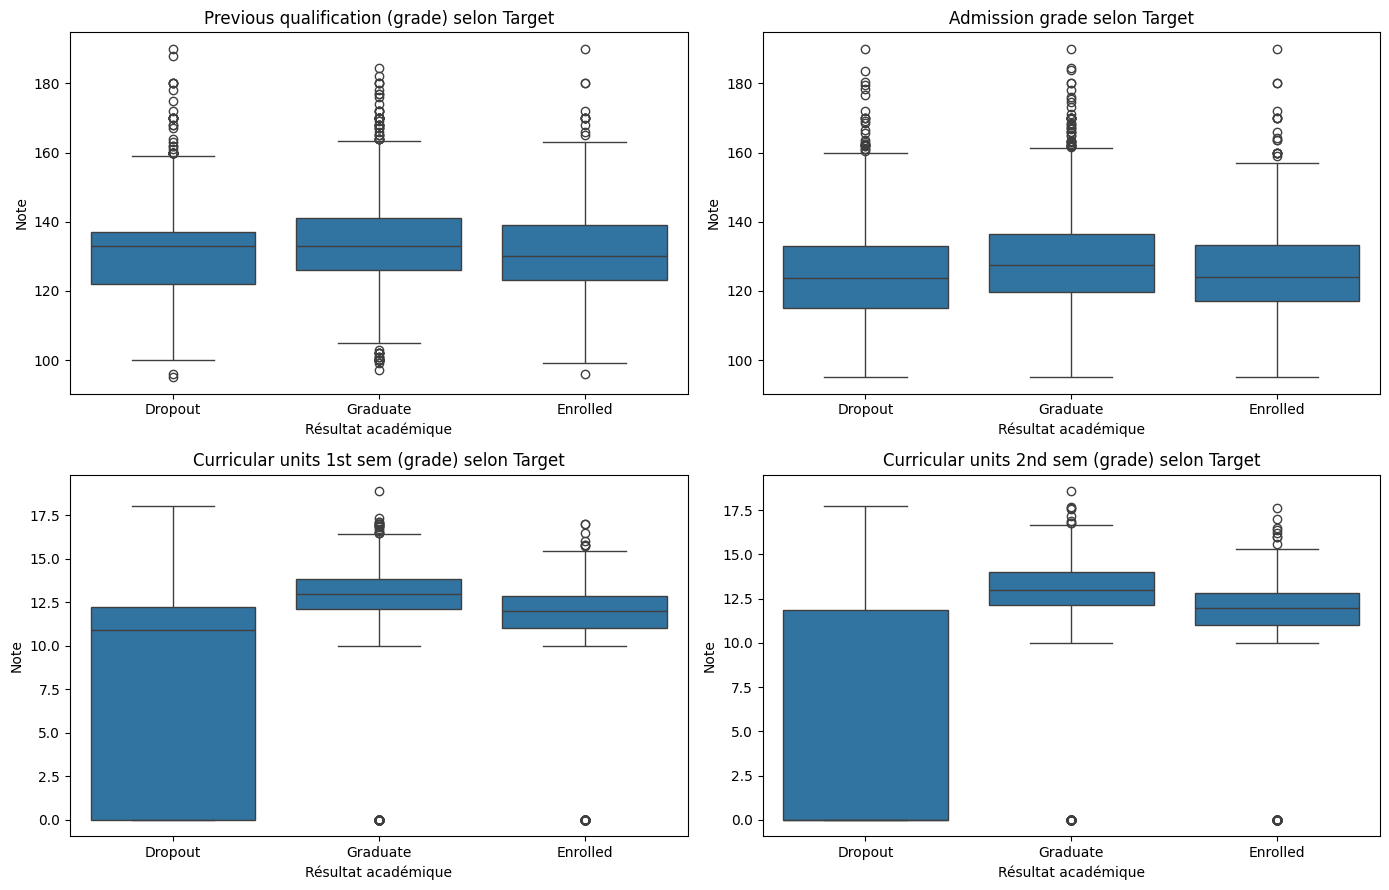

In [10]:
grade_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), grade_cols):
    sns.boxplot(data=df, x="Target", y=col, ax=ax)
    ax.set_title(f"{col} selon Target")
    ax.set_xlabel("Résultat académique")
    ax.set_ylabel("Note")

plt.tight_layout()
plt.show()

## 5. Analyse des relations entre les variables

### 5.1 Matrice de corrélation

La corrélation est utilisée pour décrire les associations linéaires entre variables quantitatives. Elle ne permet pas de conclure à une relation causale.


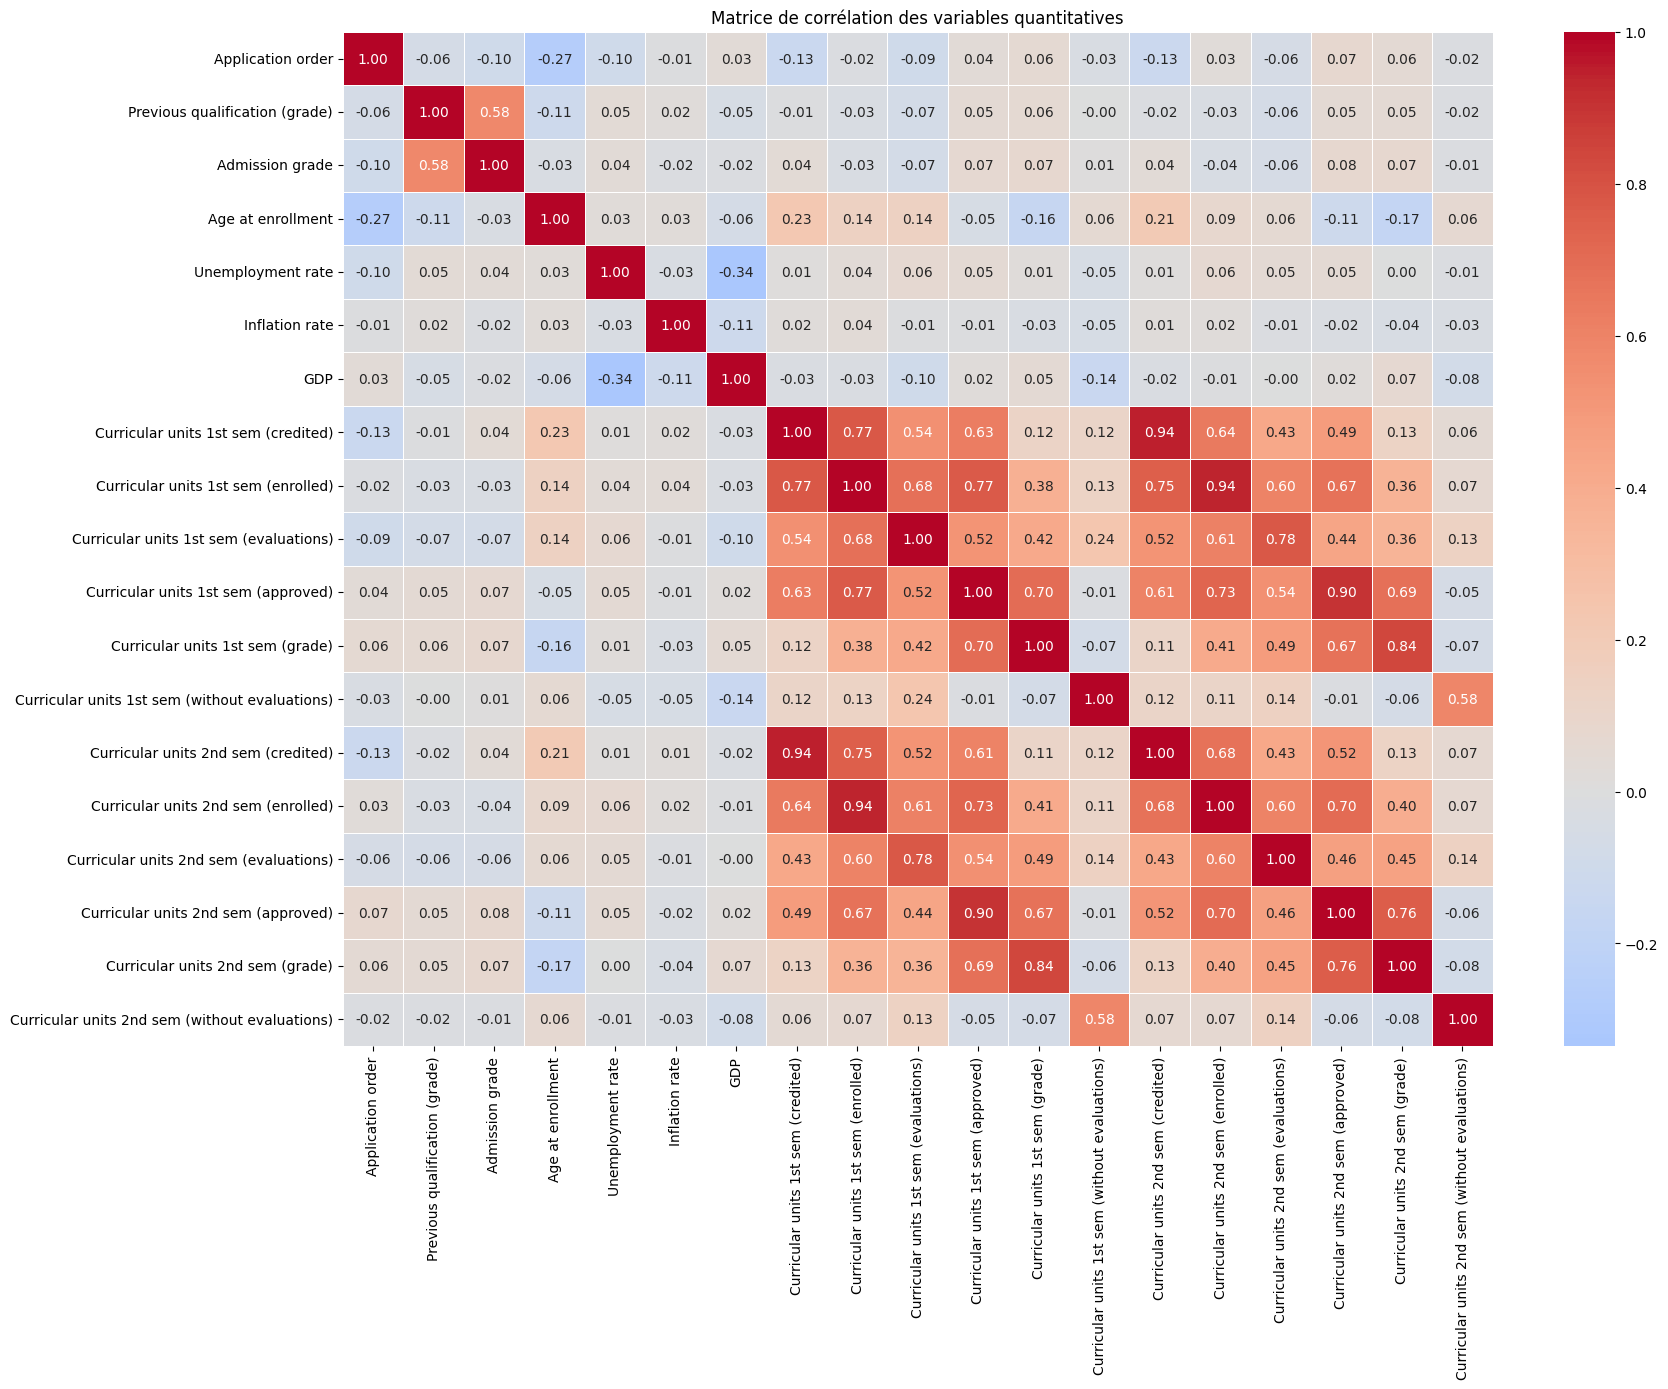

In [11]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

## 6. Équilibre des classes

La variable cible est déséquilibrée : `Graduate` représente **49,9 %** des étudiants (2 209), `Dropout` **32,1 %** (1 421) et `Enrolled` seulement **17,9 %** (794). La classe majoritaire est environ 2,8 fois plus fréquente que la classe minoritaire.

Ce déséquilibre a deux conséquences :
- l’**accuracy seule est trompeuse** : un modèle qui prédirait toujours `Graduate` aurait déjà environ 50 % de bonnes réponses. On utilise donc le **F1-score Macro** (même poids pour chaque classe) ainsi que le recall par classe ;
- la classe `Enrolled` risque d’être ignorée par l’arbre classique, d’où l’expérience avec un **arbre pondéré** (section 13).

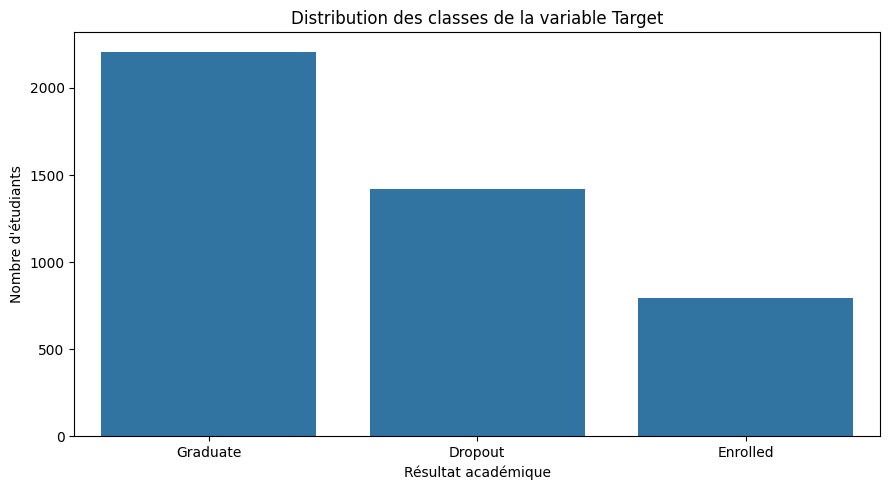

In [13]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Distribution des classes de la variable Target")
plt.xlabel("Résultat académique")
plt.ylabel("Nombre d'étudiants")

plt.tight_layout()
plt.show()

In [14]:
class_distribution = pd.DataFrame({
    "Effectif": df["Target"].value_counts(),
    "Pourcentage": df["Target"].value_counts(normalize=True) * 100
})

display(class_distribution.round(2))

,Effectif,Pourcentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


## 7. Préparation des données pour le Machine Learning

### 7.1 Séparation des variables explicatives et de la cible

`X` contient les 36 variables explicatives et `y` contient `Target`.


In [15]:
# Variables explicatives
X = df.drop(columns=["Target"])

# Variable cible
y = df["Target"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (4424, 36)
Dimensions de y : (4424,)


### 7.2 Séparation Train / Test

Le jeu de données est séparé en **80 % entraînement** et **20 % test**.

La stratification (`stratify=y`) conserve approximativement la distribution des trois classes dans les deux ensembles. Le jeu de test ne sera utilisé qu’une seule fois, à la fin, pour l’évaluation finale.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test :", X_test.shape)

print("\nDimensions y_train :", y_train.shape)
print("Dimensions y_test :", y_test.shape)

Dimensions X_train : (3539, 36)
Dimensions X_test : (885, 36)

Dimensions y_train : (3539,)
Dimensions y_test : (885,)


In [17]:
print("Distribution originale :")
display(y.value_counts(normalize=True).round(3))

print("\nDistribution Train :")
display(y_train.value_counts(normalize=True).round(3))

print("\nDistribution Test :")
display(y_test.value_counts(normalize=True).round(3))

Distribution originale :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Train :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Test :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64

### 7.3 Prétraitement utilisé par ce notebook

L’arbre de décision manuel travaille directement sur les variables originales :

- les variables catégorielles sont traitées par modalité ;
- les variables numériques sont traitées par seuil ;
- **aucune normalisation n’est nécessaire pour cet arbre**.

L’encodage one-hot et la normalisation destinés aux autres algorithmes sont réalisés dans les notebooks correspondants de l’équipe. Ils ne sont donc pas reproduits ici afin d’éviter des traitements redondants.


## 8. Arbre de décision manuel

### 8.1 Principe

L’arbre est construit à partir de l’**entropie** et du **gain d’information**. À chaque nœud, nous recherchons la séparation qui réduit le plus l’impureté de la variable cible.

Le pipeline est :

**Entropie → Gain d’information → Meilleure séparation → Construction récursive → Prédiction**



In [18]:
def entropy(y):

    probabilities = y.value_counts(normalize=True)

    entropy_value = 0

    for p in probabilities:
        entropy_value -= p * np.log2(p)

    return entropy_value

In [19]:
def information_gain(y, partitions):

    # Entropy avant splitting
    parent_entropy = entropy(y)

    # Weighted entropy aprés splitting
    weighted_entropy = 0

    for subset in partitions:

        if len(subset) == 0:
            continue

        weight = len(subset) / len(y)

        weighted_entropy += weight * entropy(subset)

    # Information Gain
    gain = parent_entropy - weighted_entropy

    return gain

In [20]:
def best_split(X, y, categorical_features, numerical_features):

    best_gain = -1
    best_feature = None
    best_split_value = None
    best_split_type = None

    # Test categorical features
    for feature in categorical_features:

        values = X[feature].dropna().unique()

        for value in values:

            left_mask = X[feature] == value
            right_mask = X[feature] != value

            left_y = y[left_mask]
            right_y = y[right_mask]

            gain = information_gain(y, [left_y, right_y])

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = value
                best_split_type = "categorical"

    # Test numerical features
    for feature in numerical_features:

        values = np.sort(X[feature].dropna().unique())

        # Calculate possible thresholds
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left_mask = X[feature] <= threshold
            right_mask = X[feature] > threshold

            left_y = y[left_mask]
            right_y = y[right_mask]

            gain = information_gain(y, [left_y, right_y])

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = threshold
                best_split_type = "numerical"

    return best_feature, best_split_value, best_split_type, best_gain

### 8.2 Construction récursive

La fonction `build_tree()` applique les mêmes principes récursivement. Plusieurs critères d’arrêt limitent la complexité : pureté du nœud, profondeur maximale, nombre minimal d’observations et gain minimal.


In [21]:
def majority_class(y):
    return y.value_counts().idxmax()

In [22]:
def build_tree(X, y, categorical_features, numerical_features,
               depth=0, max_depth=5, min_samples_split=20, min_gain=0.001):

    # Déterminer la classe majoritaire du nœud
    prediction = majority_class(y)

    # 1. Vérifier les critères d'arrêt

    # Arrêter si toutes les observations appartiennent à la même classe
    if y.nunique() == 1:
        return {"prediction": prediction}

    # Arrêter si la profondeur maximale est atteinte
    if depth >= max_depth:
        return {"prediction": prediction}

    # Arrêter si le nombre d'observations est insuffisant
    if len(y) < min_samples_split:
        return {"prediction": prediction}

    # 2. Rechercher la meilleure séparation
    feature, split_value, split_type, gain = best_split(
        X, y, categorical_features, numerical_features
    )

    # Arrêter si aucune séparation pertinente n'est trouvée
    if feature is None or gain <= min_gain:
        return {"prediction": prediction}

    # 3. Créer les deux branches

    if split_type == "numerical":
        left_mask = X[feature] <= split_value
        right_mask = X[feature] > split_value

    else:
        left_mask = X[feature] == split_value
        right_mask = X[feature] != split_value

    # Éviter de créer une branche vide
    if not left_mask.any() or not right_mask.any():
        return {"prediction": prediction}

    # 4. Construire récursivement les deux sous-arbres

    left_subtree = build_tree(
        X.loc[left_mask],
        y.loc[left_mask],
        categorical_features,
        numerical_features,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    right_subtree = build_tree(
        X.loc[right_mask],
        y.loc[right_mask],
        categorical_features,
        numerical_features,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    # Retourner le nœud avec ses informations de séparation
    return {
        "feature": feature,
        "split_value": split_value,
        "split_type": split_type,
        "gain": gain,
        "n_samples": len(y),
        "left": left_subtree,
        "right": right_subtree,
        "prediction": prediction
    }

### 8.3 Fonction de prédiction

Pour une nouvelle observation, l’algorithme parcourt l’arbre depuis la racine jusqu’à une feuille et retourne la classe associée.


In [23]:
def predict_one(tree, sample):


    # Vérifier si le nœud actuel est une feuille
    if "feature" not in tree:
        return tree["prediction"]

    # Récupérer les informations du nœud
    feature = tree["feature"]
    split_value = tree["split_value"]
    split_type = tree["split_type"]

    # Choisir la branche selon le type de variable
    if split_type == "numerical":

        if sample[feature] <= split_value:
            return predict_one(tree["left"], sample)

        else:
            return predict_one(tree["right"], sample)

    else:

        if sample[feature] == split_value:
            return predict_one(tree["left"], sample)

        else:
            return predict_one(tree["right"], sample)

In [24]:
def predict(tree, X):


    predictions = []

    for _, sample in X.iterrows():

        prediction = predict_one(tree, sample)

        predictions.append(prediction)

    return pd.Series(predictions, index=X.index)

In [25]:
def classification_metrics(y_true, y_pred, classes):
    """Calcule precision, recall et F1-score pour chaque classe."""
    confusion = pd.crosstab(
        y_true, y_pred,
        rownames=["Classe réelle"],
        colnames=["Classe prédite"],
        dropna=False
    ).reindex(index=classes, columns=classes, fill_value=0)

    rows = []
    for classe in classes:
        TP = confusion.loc[classe, classe]
        FP = confusion[classe].sum() - TP
        FN = confusion.loc[classe].sum() - TP

        precision = TP / (TP + FP) if TP + FP > 0 else 0
        recall = TP / (TP + FN) if TP + FN > 0 else 0
        f1 = (2 * precision * recall / (precision + recall)
               if precision + recall > 0 else 0)

        rows.append({
            "Classe": classe,
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1
        })

    return pd.DataFrame(rows), confusion



## 9. Pipeline de sélection des variables

Pour éviter toute fuite d’information, le jeu de test est laissé totalement intact.

Le jeu d’entraînement est à son tour séparé en :

- **Sous-entraînement** : construction de l’arbre utilisé pour calculer l’importance des variables et entraîner les modèles comparés.
- **Validation** : comparaison des configurations Top 5, Top 10 et toutes les variables, puis sélection des hyperparamètres.
- **Test final** : utilisé uniquement après toutes les décisions de modélisation.


In [26]:
X_train_tree = X_train.copy()
y_train_tree = y_train.copy()
X_test_tree = X_test.copy()
y_test_tree = y_test.copy()

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_tree,
    y_train_tree,
    test_size=0.20,
    random_state=42,
    stratify=y_train_tree
)

print("Sous-entraînement :", X_subtrain.shape)
print("Validation        :", X_val.shape)
print("Test final        :", X_test_tree.shape)



Sous-entraînement : (2831, 36)
Validation        : (708, 36)
Test final        : (885, 36)


In [27]:
# Ordre fixe des classes pour les évaluations
classes = ["Dropout", "Enrolled", "Graduate"]


### 9.1 Vérification de la séparation

Les distributions de classes sont comparées pour vérifier que la stratification a été conservée. Le test n’est pas utilisé pour sélectionner les variables ni les hyperparamètres.


In [28]:
distribution_split = pd.DataFrame({
    "Train complet": y_train_tree.value_counts(normalize=True),
    "Sous-entraînement": y_subtrain.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test_tree.value_counts(normalize=True)
}).mul(100).round(2)

display(distribution_split)



,Train complet,Sous-entraînement,Validation,Test
Target,,,,
Graduate,49.93,49.91,50.00,49.94
Dropout,32.13,32.14,32.06,32.09
Enrolled,17.94,17.94,17.94,17.97


### 9.2 Première séparation de l’arbre

Pour illustrer le fonctionnement de `best_split()`, nous recherchons la meilleure séparation **uniquement sur le sous-ensemble d’entraînement**. Ainsi, même cette étape pédagogique ne consulte pas la validation ni le test.


In [29]:
best_feature, split_value, split_type, gain = best_split(
    X_subtrain, y_subtrain, categorical_cols, numerical_cols
)

print("Variable sélectionnée :", best_feature)
print("Type de séparation    :", split_type)
print("Valeur du seuil       :", split_value)
print("Gain d'information    :", round(gain, 5))



Variable sélectionnée : Curricular units 2nd sem (approved)
Type de séparation    : numerical
Valeur du seuil       : 4.5
Gain d'information    : 0.32923


Le gain d’information indique la réduction d’impureté obtenue par la séparation. Il ne représente pas un pourcentage d’étudiants et ne doit pas être interprété comme une causalité.


### 9.3 Calcul de l’importance des variables

Un arbre est construit sur le **sous-ensemble d’entraînement uniquement**. L’importance d’une variable est calculée à partir de sa contribution cumulée au gain d’information, pondérée par le nombre d’observations du nœud.

Cette importance décrit la contribution de la variable dans notre arbre ; elle ne représente pas une relation causale.


In [30]:
tree_selection = build_tree(
    X_subtrain,
    y_subtrain,
    categorical_cols,
    numerical_cols,
    max_depth=5,
    min_samples_split=20,
    min_gain=0.001
)

def calculate_feature_importance(tree, importances=None):
    if importances is None:
        importances = {}

    if "feature" not in tree:
        return importances

    feature = tree["feature"]
    contribution = tree["n_samples"] * tree["gain"]
    importances[feature] = importances.get(feature, 0) + contribution

    calculate_feature_importance(tree["left"], importances)
    calculate_feature_importance(tree["right"], importances)
    return importances

selection_importances = calculate_feature_importance(tree_selection)
total_importance = sum(selection_importances.values())

selection_importances = {
    feature: value / total_importance
    for feature, value in selection_importances.items()
}

importance_df = (
    pd.DataFrame(list(selection_importances.items()),
                 columns=["Feature", "Importance"])
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df)



,Feature,Importance
0,Curricular units 2nd sem (approved),0.653547
1,Tuition fees up to date,0.101643
2,Course,0.076028
3,Curricular units 1st sem (evaluations),0.056923
4,Curricular units 1st sem (approved),0.035360
5,Curricular units 2nd sem (enrolled),0.019743
6,Previous qualification (grade),0.013801
7,Admission grade,0.011522
8,Curricular units 2nd sem (credited),0.008184
9,Curricular units 2nd sem (grade),0.007664


### 9.4 Visualisation des variables les plus importantes


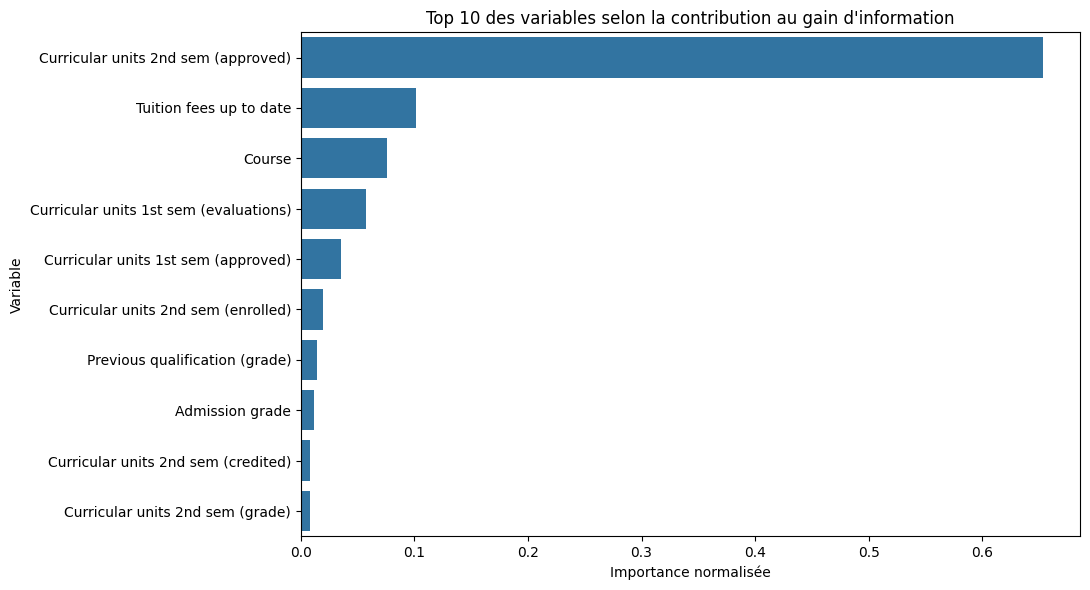

In [31]:
top_10_plot = importance_df.head(10)

plt.figure(figsize=(11, 6))
sns.barplot(data=top_10_plot, x="Importance", y="Feature")
plt.title("Top 10 des variables selon la contribution au gain d'information")
plt.xlabel("Importance normalisée")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()



### Interprétation de l'importance des variables

La première séparation de l'arbre se fait sur `Curricular units 2nd sem (approved)` avec un seuil de 4,5 unités validées (gain d'information de 0,329). Cette variable concentre à elle seule **65,4 %** de l'importance totale. Viennent ensuite `Tuition fees up to date` (10,2 %), `Course` (7,6 %), `Curricular units 1st sem (evaluations)` (5,7 %) et `Curricular units 1st sem (approved)` (3,5 %). Ces cinq variables représentent **92,3 %** de l'importance, et seules 13 variables sur 36 sont utilisées par l'arbre.

Trois remarques importantes :
- Les variables les plus discriminantes sont liées aux **résultats académiques** (unités validées, évaluations) et à la **situation financière** (frais de scolarité à jour). Les variables socio-démographiques (profession et qualification des parents, nationalité, etc.) jouent un rôle très faible.
- Plusieurs variables dominantes proviennent du **2e semestre** : elles ne sont connues que tard dans l'année. Le modèle est donc utile pour identifier les étudiants à risque en cours de parcours, mais moins pour une détection précoce.
- Le gain d'information favorise les variables à nombreuses modalités. La présence de `Course` peut en partie refléter ce biais, d'où l'intérêt de comparer avec le gain ratio.

## 10. Sélection des variables

Trois configurations sont comparées :

- **Top 5** : cinq variables les plus importantes ;
- **Top 10** : dix variables les plus importantes ;
- **Toutes** : les 36 variables disponibles.

Cette comparaison est réalisée uniquement sur le sous-entraînement et la validation. Le test reste intact.


In [32]:
top_5_features = importance_df.head(5)["Feature"].tolist()
top_10_features = importance_df.head(10)["Feature"].tolist()
all_features = X_subtrain.columns.tolist()

feature_configurations = {
    "Top 5": top_5_features,
    "Top 10": top_10_features,
    "Toutes les features": all_features
}

config_types = {
    name: {
        "categorical": [col for col in categorical_cols if col in features],
        "numerical": [col for col in numerical_cols if col in features]
    }
    for name, features in feature_configurations.items()
}

for name, features in feature_configurations.items():
    print(f"{name} ({len(features)} variables) :")
    print(features)



Top 5 (5 variables) :
['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Course', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)']
Top 10 (10 variables) :
['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Course', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (enrolled)', 'Previous qualification (grade)', 'Admission grade', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (grade)']
Toutes les features (36 variables) :
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'Internati

### 10.1 Comparaison sur le jeu de validation

Chaque configuration est entraînée sur `X_subtrain` puis évaluée sur `X_val`. Le critère principal est le **F1-score Macro**, car il donne le même poids aux trois classes et évite de juger le modèle uniquement à partir de la classe majoritaire.


In [33]:
trees = {}
comparison_results = []

for name, features in feature_configurations.items():
    categorical = config_types[name]["categorical"]
    numerical = config_types[name]["numerical"]

    tree = build_tree(
        X_subtrain[features],
        y_subtrain,
        categorical,
        numerical,
        max_depth=5,
        min_samples_split=20,
        min_gain=0.001
    )
    trees[name] = tree

    predictions = predict(tree, X_val[features])
    metrics_val, _ = classification_metrics(y_val, predictions, classes)

    comparison_results.append({
        "Configuration": name,
        "Nombre de features": len(features),
        "Accuracy": (predictions == y_val).mean(),
        "Recall Dropout": metrics_val.loc[metrics_val["Classe"] == "Dropout", "Recall"].iloc[0],
        "Recall Enrolled": metrics_val.loc[metrics_val["Classe"] == "Enrolled", "Recall"].iloc[0],
        "F1-score Macro": metrics_val["F1-score"].mean()
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(
    "F1-score Macro", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))



,Configuration,Nombre de features,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,Toutes les features,36,0.7472,0.7137,0.4016,0.6775
1,Top 10,10,0.7458,0.7137,0.3937,0.6747
2,Top 5,5,0.7556,0.7048,0.2677,0.6572


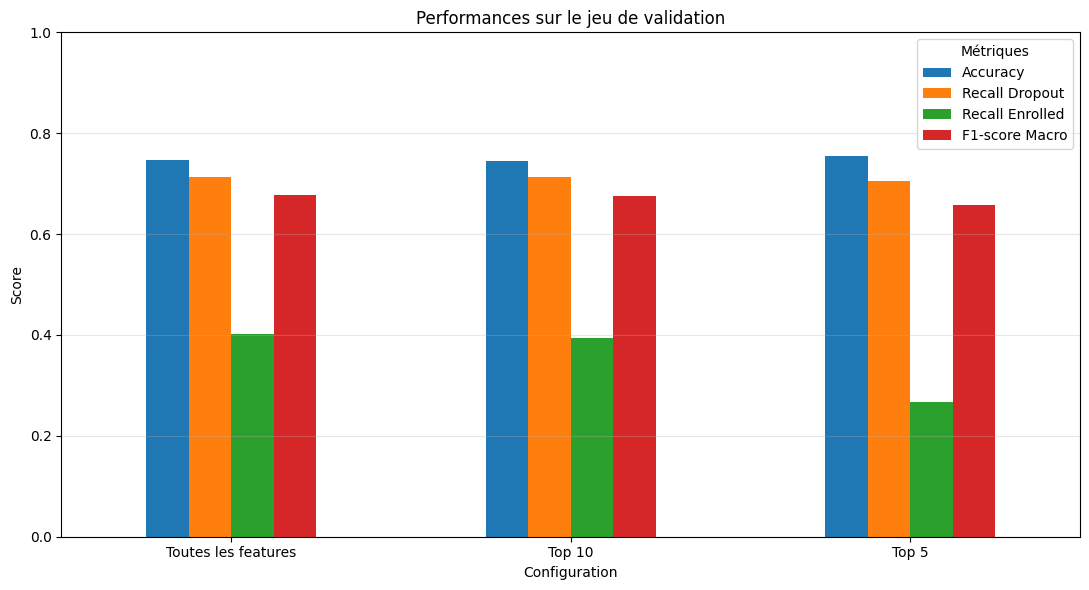

In [34]:
comparison_plot = comparison_df.set_index("Configuration")[
    ["Accuracy", "Recall Dropout", "Recall Enrolled", "F1-score Macro"]
]
comparison_plot.plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0)
plt.title("Performances sur le jeu de validation")
plt.xlabel("Configuration")
plt.ylabel("Score")
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Interprétation de la comparaison

Sur le jeu de validation, les trois configurations obtiennent des performances proches :

| Configuration | Accuracy | Recall Enrolled | F1-score Macro |
|---|---|---|---|
| Toutes les variables (36) | 0,7472 | 0,4016 | 0,6775 |
| Top 10 | 0,7458 | 0,3937 | 0,6747 |
| Top 5 | 0,7556 | 0,2677 | 0,6572 |

Réduire de 36 à 10 variables ne fait perdre que 0,003 de F1 macro, un écart inférieur au bruit attendu sur 708 observations. Avec 5 variables, l'accuracy est légèrement meilleure, mais le recall de la classe `Enrolled` chute à 0,27 : le modèle devient trop centré sur les classes majoritaires. Cinq variables sont donc insuffisantes.

### 10.2 Choix de la configuration

Nous retenons le **Top 10** (les 10 variables les plus importantes selon l’arbre).

Sur le jeu de validation, le Top 10 obtient un F1-score Macro de 0,6747, contre 0,6775 avec les 36 variables. L’écart est très faible (0,003) : réduire le nombre de variables ne dégrade presque pas la performance. Un modèle avec moins de variables est plus simple et plus facile à interpréter.

Avec seulement 5 variables, le F1-score Macro tombe à 0,6572, et le recall de `Enrolled` chute à 0,27. Cinq variables sont donc insuffisantes.

Ce choix est fait à partir de la validation, sans utiliser le jeu de test.

In [35]:
# Configuration retenue : les 10 variables les plus importantes
selected_config = "Top 10"
selected_features = feature_configurations[selected_config]

print("Configuration sélectionnée :", selected_config)
print("Nombre de variables :", len(selected_features))
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

Configuration sélectionnée : Top 10
Nombre de variables : 10
1. Curricular units 2nd sem (approved)
2. Tuition fees up to date
3. Course
4. Curricular units 1st sem (evaluations)
5. Curricular units 1st sem (approved)
6. Curricular units 2nd sem (enrolled)
7. Previous qualification (grade)
8. Admission grade
9. Curricular units 2nd sem (credited)
10. Curricular units 2nd sem (grade)


### 10.3 Corrélation entre les variables retenues

Avant de transmettre les variables sélectionnées à la régression logistique, au SVM et à K-means, on vérifie leur redondance. Deux variables fortement corrélées apportent presque la même information ; elles peuvent déstabiliser les coefficients de la régression logistique et compter deux fois dans les distances de K-means.

La corrélation est calculée sur le **jeu d’entraînement uniquement** et seulement pour les variables numériques retenues (les variables catégorielles comme `Tuition fees up to date` ou `Course` en sont exclues).

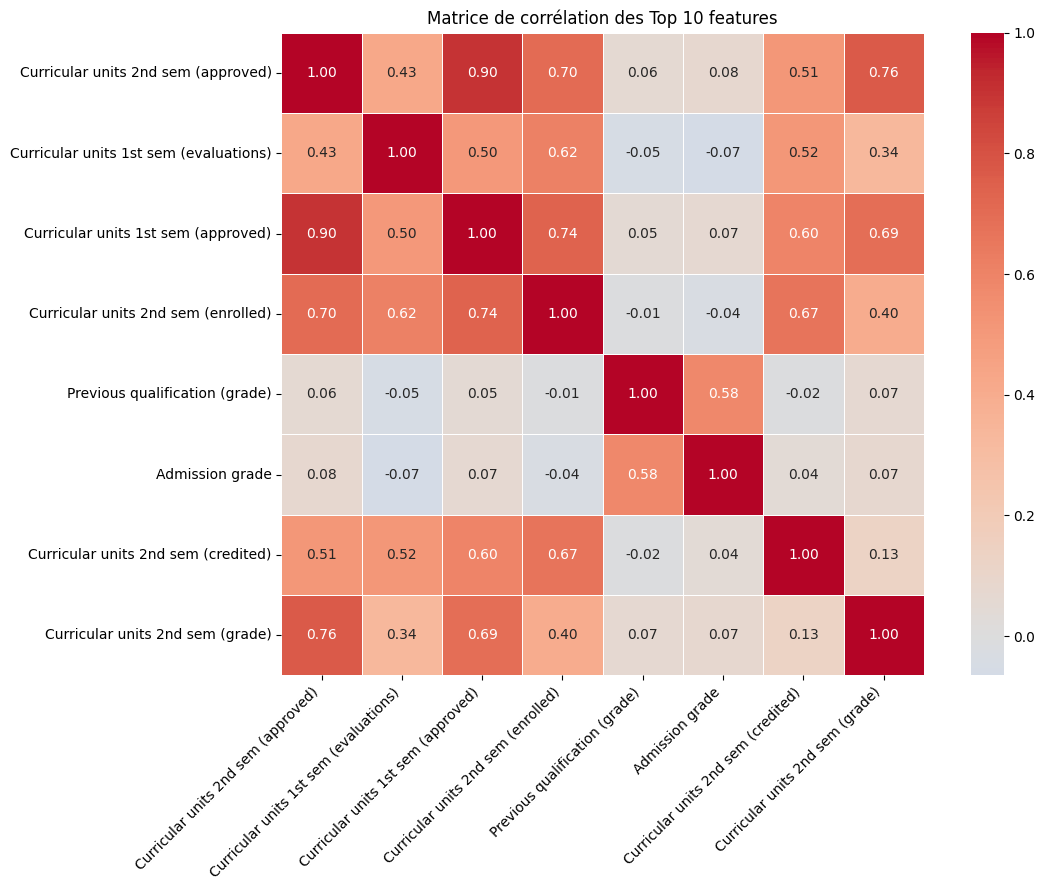

In [36]:
# 1. Récupérer les variables numériques parmi les Top 10 features
top_10_numerical = [
    col for col in top_10_features
    if col in numerical_cols
]

# 2. Calculer la matrice de corrélation
correlation_matrix = X_subtrain[top_10_numerical].corr(
    method="pearson"
)

# 3. Visualiser la matrice
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Matrice de corrélation des Top 10 features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Interprétation

Parmi les 10 variables retenues, 8 sont numériques ; la matrice de corrélation (calculée sur le sous-entraînement) montre deux groupes distincts :

- **Un bloc « parcours académique »** (unités validées, inscrites, créditées et note du 2e semestre) dont les variables sont fortement liées entre elles. La paire la plus corrélée est `Curricular units 1st sem (approved)` / `2nd sem (approved)` (**r = 0,90**), suivie de `2nd sem (approved)` / `2nd sem (grade)` (0,76) et `1st sem (approved)` / `2nd sem (enrolled)` (0,74). Un étudiant qui valide beaucoup d’unités au 1er semestre en valide aussi beaucoup au 2e.
- **Un bloc « profil d’entrée »** (`Previous qualification (grade)` et `Admission grade`, r = 0,58), pratiquement indépendant du bloc académique (|r| ≤ 0,08).

**Conséquences pour la suite du pipeline :**
- La corrélation de 0,90 ne gêne pas l’arbre de décision, qui choisit simplement la meilleure séparation. Elle est en revanche problématique pour la **régression logistique** (coefficients instables). On utilisera une régularisation L2, ou on testera le modèle sans `1st sem (approved)`.
- Pour **K-means**, six variables sur huit appartiennent au bloc académique : les distances seront dominées par ce bloc, et les clusters reflèteront surtout la réussite académique. Une réduction de dimension (ACP) ou le retrait des variables redondantes peut être envisagé.
- La sélection du Top 10 est conservée : les deux blocs sont complémentaires, et une seule paire dépasse 0,8.
- Les variables catégorielles retenues (`Tuition fees up to date`, `Course`) ne sont pas analysées ici ; leur lien avec `Target` pourrait être étudié avec un test du χ².

## 11. Optimisation des hyperparamètres

Les hyperparamètres contrôlent la complexité de l’arbre :

- `max_depth` : profondeur maximale ;
- `min_samples_split` : nombre minimal d’observations nécessaire pour diviser un nœud ;
- `min_gain` : gain minimal accepté pour effectuer une séparation.

12 combinaisons sont testées. Elles sont entraînées sur le sous-entraînement et évaluées sur la validation. **Le jeu de test n’intervient jamais dans cette optimisation.**


In [37]:
from itertools import product

X_subtrain_selected = X_subtrain[selected_features]
X_val_selected = X_val[selected_features]
categorical_selected = config_types[selected_config]["categorical"]
numerical_selected = config_types[selected_config]["numerical"]

depth_values = [3, 5, 7]
min_samples_values = [20, 40]
gain_values = [0.001, 0.005]

tuning_results = []

for depth, min_samples, gain in product(
    depth_values, min_samples_values, gain_values
):
    tree = build_tree(
        X_subtrain_selected,
        y_subtrain,
        categorical_selected,
        numerical_selected,
        max_depth=depth,
        min_samples_split=min_samples,
        min_gain=gain
    )

    predictions = predict(tree, X_val_selected)
    metrics_val, _ = classification_metrics(y_val, predictions, classes)

    tuning_results.append({
        "Max depth": depth,
        "Min samples split": min_samples,
        "Min gain": gain,
        "Accuracy": (predictions == y_val).mean(),
        "Recall Dropout": metrics_val.loc[metrics_val["Classe"] == "Dropout", "Recall"].iloc[0],
        "Recall Enrolled": metrics_val.loc[metrics_val["Classe"] == "Enrolled", "Recall"].iloc[0],
        "F1-score Macro": metrics_val["F1-score"].mean()
    })

tuning_df = pd.DataFrame(tuning_results).sort_values(
    "F1-score Macro", ascending=False
).reset_index(drop=True)

display(tuning_df.round(4))



,Max depth,Min samples split,Min gain,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,5,40,0.001,0.7514,0.7313,0.3937,0.6800
1,5,40,0.005,0.7514,0.7313,0.3937,0.6800
2,5,20,0.001,0.7458,0.7137,0.3937,0.6747
3,5,20,0.005,0.7458,0.7137,0.3937,0.6747
4,3,40,0.005,0.7387,0.7357,0.4094,0.6724
5,3,40,0.001,0.7387,0.7357,0.4094,0.6724
6,3,20,0.005,0.7387,0.7357,0.4094,0.6724
7,3,20,0.001,0.7387,0.7357,0.4094,0.6724
8,7,40,0.005,0.7415,0.7885,0.1811,0.6214
9,7,40,0.001,0.7415,0.7885,0.1811,0.6214


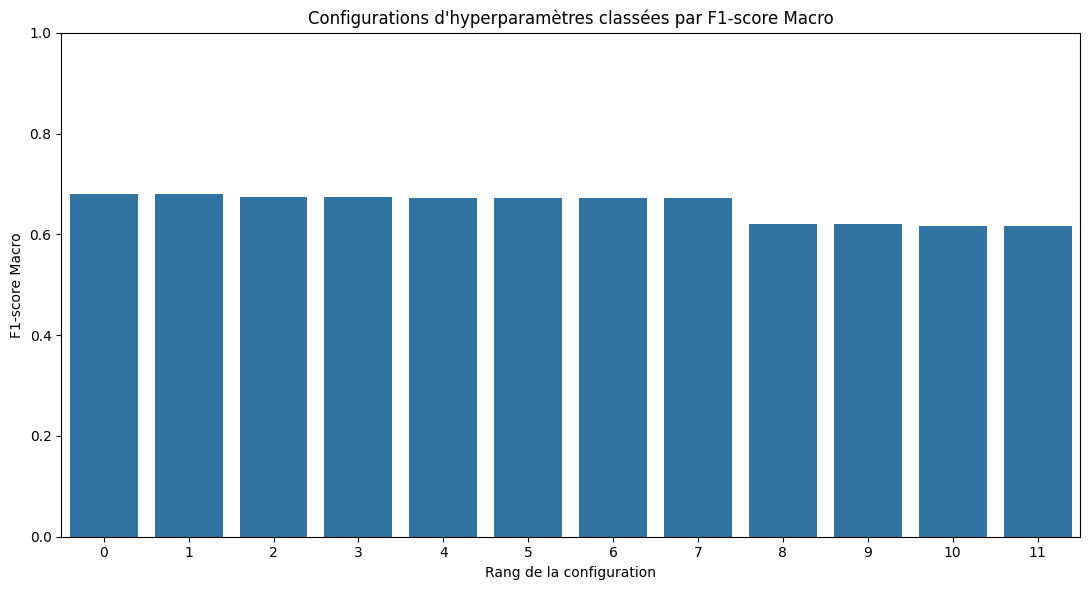

In [38]:
plt.figure(figsize=(11, 6))
sns.barplot(data=tuning_df, x=tuning_df.index.astype(str), y="F1-score Macro")
plt.title("Configurations d'hyperparamètres classées par F1-score Macro")
plt.xlabel("Rang de la configuration")
plt.ylabel("F1-score Macro")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()



In [39]:
best_config = tuning_df.iloc[0]
best_params = {
    "max_depth": int(best_config["Max depth"]),
    "min_samples_split": int(best_config["Min samples split"]),
    "min_gain": float(best_config["Min gain"])
}

print("Meilleurs hyperparamètres selon le F1-score Macro de validation :")
print(best_params)
print("F1-score Macro de validation :", round(best_config["F1-score Macro"], 4))



Meilleurs hyperparamètres selon le F1-score Macro de validation :
{'max_depth': 5, 'min_samples_split': 40, 'min_gain': 0.001}
F1-score Macro de validation : 0.68


### Interprétation du tuning

Nous avons testé 12 configurations en faisant varier la profondeur de l'arbre, le nombre minimum d'observations pour diviser un nœud et le gain minimum.

La meilleure configuration selon le F1-score Macro sur la validation est :

- max_depth = 5

- min_samples_split = 40

- min_gain = 0.001

Elle obtient une accuracy de 0,7514 et un F1-score Macro de 0,6800.

Une profondeur de 3 donne un résultat légèrement inférieur (F1 Macro = 0,6724). Avec une profondeur de 7, le résultat baisse davantage (0,6214), notamment parce que le recall de Enrolled tombe à 0,1811.

Enfin, les valeurs 0,001 et 0,005 de min_gain donnent exactement les mêmes résultats dans nos essais.

Nous retenons donc une profondeur de 5 et un minimum de 40 observations par séparation.

## 12. Modèle final et évaluation sur le test

Toutes les décisions précédentes — sélection des variables et hyperparamètres — ont été prises sans utiliser le test.

Le modèle final est maintenant reconstruit sur **l’ensemble du train** avec les variables sélectionnées et les meilleurs hyperparamètres. Le test est utilisé une seule fois pour mesurer la performance finale.


In [40]:
X_train_final = X_train_tree[selected_features]
X_test_final = X_test_tree[selected_features]

final_tree = build_tree(
    X_train_final,
    y_train_tree,
    categorical_selected,
    numerical_selected,
    **best_params
)

y_pred_final = predict(final_tree, X_test_final)

print("Arbre final construit.")
print("Configuration :", selected_config)
print("Nombre de variables :", len(selected_features))
print("Nombre d'observations d'entraînement :", len(X_train_final))



Arbre final construit.
Configuration : Top 10
Nombre de variables : 10
Nombre d'observations d'entraînement : 3539


### 12.1 Évaluation finale

Les performances sont calculées sur les 20 % de données conservées comme test. On présente l’accuracy, la précision, le rappel, le F1-score par classe, le F1-score Macro et la matrice de confusion.


Accuracy finale : 0.7458 (74.58 %)
F1-score Macro  : 0.6606


,Classe,Precision,Recall,F1-score
0,Dropout,0.8524,0.6303,0.7247
1,Enrolled,0.4870,0.3522,0.4088
2,Graduate,0.7589,0.9615,0.8483


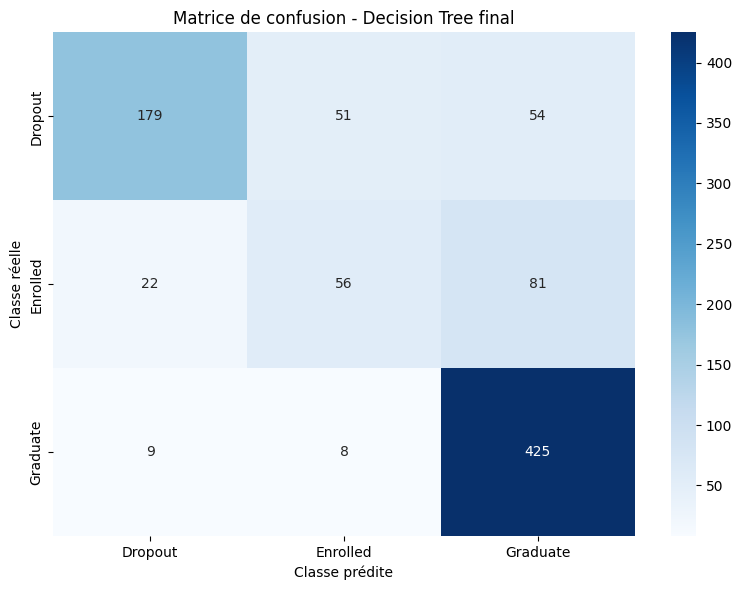

In [41]:
metrics_final, confusion_final = classification_metrics(
    y_test_tree, y_pred_final, classes
)
accuracy_final = (y_pred_final == y_test_tree).mean()
f1_macro_final = metrics_final["F1-score"].mean()

print(f"Accuracy finale : {accuracy_final:.4f} ({accuracy_final * 100:.2f} %)")
print(f"F1-score Macro  : {f1_macro_final:.4f}")

display(metrics_final.round(4))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_final, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion - Decision Tree final")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()



### Interprétation de l’évaluation finale

Sur le jeu de test, l'arbre classique obtient une accuracy de 74,58 % et un F1-score Macro de 0,6606.

Les résultats varient selon les classes :

Graduate est la classe la mieux reconnue, avec un recall de 0,9615.

Dropout obtient un recall de 0,6303.

Enrolled reste la classe la plus difficile à reconnaître, avec un recall de seulement 0,3522.

Le modèle reconnaît donc très bien les étudiants qui terminent leur formation, mais il détecte moins bien les étudiants encore inscrits.

Le F1-score Macro permet de tenir compte des trois classes avec la même importance. Il donne ici une vision plus complète que l'accuracy seule.


## 13. Amélioration : Arbre de décision pondéré

L’arbre classique peut favoriser les classes les plus représentées. Nous testons donc une variante pondérée afin de donner davantage d’importance aux classes minoritaires, en particulier `Enrolled`.

Cette expérience est réalisée après la sélection du modèle classique. Elle ne modifie pas le jeu de test : les deux modèles sont comparés sur le même test final.


### 13.1 Calcul des poids de classes

Nous utilisons des poids inversement proportionnels à la fréquence des classes :

$$w_c = \frac{N}{K \times N_c}$$

avec `N` le nombre total d’observations, `K` le nombre de classes et `N_c` l’effectif de la classe `c`.


In [42]:
nombre_classes = y_train_tree.nunique()
nombre_observations = len(y_train_tree)
effectifs_classes = y_train_tree.value_counts()

poids_classes = {
    classe: nombre_observations / (nombre_classes * effectif)
    for classe, effectif in effectifs_classes.items()
}

print("Poids des classes :")
for classe, poids in poids_classes.items():
    print(f"{classe}: {poids:.4f}")



Poids des classes :
Graduate: 0.6676
Dropout: 1.0375
Enrolled: 1.8577


### 13.2 Entropie et gain d’information pondérés

La version pondérée reprend la logique de l’arbre classique, mais les observations appartenant aux classes minoritaires ont davantage d’influence dans le calcul de l’impureté et du gain.


In [43]:
def weighted_entropy(y, poids_classes):
    # Si le nœud est vide
    if len(y) == 0:
        return 0

    # Calcul du poids total du nœud
    poids_total = sum(poids_classes[classe] for classe in y)

    entropie = 0

    # Parcours des classes présentes dans le nœud
    for classe in y.unique():

        # Nombre d'observations de cette classe
        effectif = (y == classe).sum()

        # Poids total de cette classe
        poids_classe = effectif * poids_classes[classe]

        # Probabilité pondérée
        probabilite = poids_classe / poids_total

        if probabilite > 0:
            entropie -= probabilite * np.log2(probabilite)

    return entropie

In [44]:
def weighted_information_gain(y, left_y, right_y, poids_classes):

    # Entropie pondérée du nœud parent
    entropie_parent = weighted_entropy(y, poids_classes)

    # Poids total du parent
    poids_parent = sum(poids_classes[classe] for classe in y)

    # Poids des deux branches
    poids_gauche = sum(poids_classes[classe] for classe in left_y)
    poids_droite = sum(poids_classes[classe] for classe in right_y)

    # Vérifier que les branches ne sont pas vides
    if poids_gauche == 0 or poids_droite == 0:
        return 0

    # Proportions pondérées
    proportion_gauche = poids_gauche / poids_parent
    proportion_droite = poids_droite / poids_parent

    # Entropies des deux branches
    entropie_gauche = weighted_entropy(left_y, poids_classes)
    entropie_droite = weighted_entropy(right_y, poids_classes)

    # Gain d'information pondéré
    gain = entropie_parent - (
        proportion_gauche * entropie_gauche
        + proportion_droite * entropie_droite
    )

    return gain

In [45]:
def weighted_best_split(X, y, categorical_features,
                        numerical_features, poids_classes):

    best_gain = -1
    best_feature = None
    best_split_value = None
    best_split_type = None

    # Tester les variables catégorielles
    for feature in categorical_features:

        values = X[feature].dropna().unique()

        for value in values:

            left_mask = X[feature] == value
            right_mask = X[feature] != value

            left_y = y.loc[left_mask]
            right_y = y.loc[right_mask]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            gain = weighted_information_gain(
                y, left_y, right_y, poids_classes
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = value
                best_split_type = "categorical"

    # Tester les variables numériques
    for feature in numerical_features:

        values = np.sort(X[feature].dropna().unique())

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left_mask = X[feature] <= threshold
            right_mask = X[feature] > threshold

            left_y = y.loc[left_mask]
            right_y = y.loc[right_mask]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            gain = weighted_information_gain(
                y, left_y, right_y, poids_classes
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = threshold
                best_split_type = "numerical"

    return best_feature, best_split_value, best_split_type, best_gain

In [46]:
def weighted_majority_class(y, poids_classes):

    poids_par_classe = {}

    for classe in y.unique():

        effectif = (y == classe).sum()

        poids_par_classe[classe] = (
            effectif * poids_classes[classe]
        )

    return max(poids_par_classe, key=poids_par_classe.get)

In [47]:
def build_weighted_tree(X, y, categorical_features, numerical_features,
                        poids_classes, depth=0, max_depth=5,
                        min_samples_split=40, min_gain=0.001):

    # Déterminer la classe majoritaire pondérée
    prediction = weighted_majority_class(y, poids_classes)

    # Arrêter si le nœud est pur
    if y.nunique() == 1:
        return {"prediction": prediction}

    # Arrêter si la profondeur maximale est atteinte
    if depth >= max_depth:
        return {"prediction": prediction}

    # Arrêter si le nombre d'observations est insuffisant
    if len(y) < min_samples_split:
        return {"prediction": prediction}

    # Rechercher la meilleure séparation pondérée
    feature, split_value, split_type, gain = weighted_best_split(
        X, y, categorical_features, numerical_features, poids_classes
    )

    # Arrêter si aucune séparation pertinente n'est trouvée
    if feature is None or gain <= min_gain:
        return {"prediction": prediction}

    # Créer les deux branches
    if split_type == "numerical":
        left_mask = X[feature] <= split_value
        right_mask = X[feature] > split_value

    else:
        left_mask = X[feature] == split_value
        right_mask = X[feature] != split_value

    # Éviter les branches vides
    if not left_mask.any() or not right_mask.any():
        return {"prediction": prediction}

    # Construire récursivement les deux sous-arbres
    left_subtree = build_weighted_tree(
        X.loc[left_mask],
        y.loc[left_mask],
        categorical_features,
        numerical_features,
        poids_classes,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    right_subtree = build_weighted_tree(
        X.loc[right_mask],
        y.loc[right_mask],
        categorical_features,
        numerical_features,
        poids_classes,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    # Retourner le nœud
    return {
        "feature": feature,
        "split_value": split_value,
        "split_type": split_type,
        "gain": gain,
        "n_samples": len(y),
        "left": left_subtree,
        "right": right_subtree,
        "prediction": prediction
    }

### 13.3 Entraînement et évaluation

L’arbre pondéré utilise la même configuration de variables et les mêmes hyperparamètres que le modèle classique final. Cela permet d’isoler l’effet de la pondération.


Accuracy pondérée : 0.6554 (65.54 %)
F1-score Macro    : 0.6364


,Classe,Precision,Recall,F1-score
0,Dropout,0.8265,0.6373,0.7197
1,Enrolled,0.3303,0.6792,0.4444
2,Graduate,0.8584,0.6584,0.7452


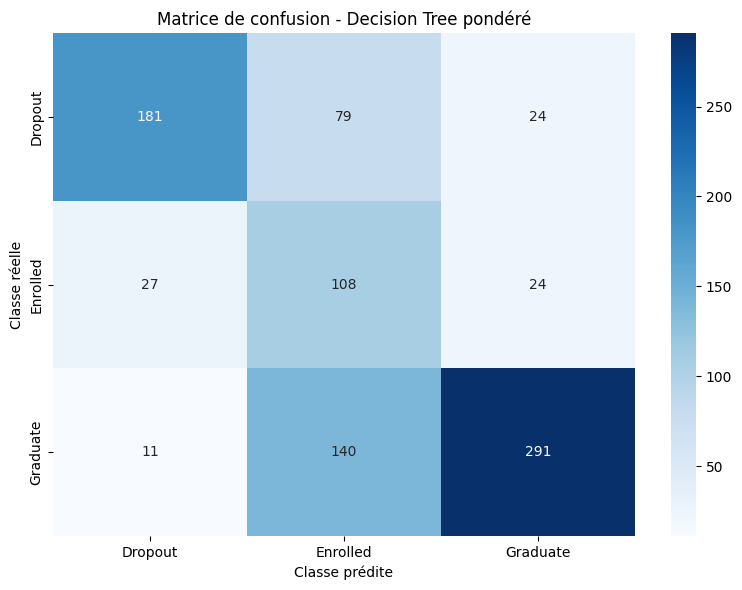

In [48]:
weighted_tree = build_weighted_tree(
    X_train_final,
    y_train_tree,
    categorical_selected,
    numerical_selected,
    poids_classes,
    **best_params
)

y_pred_weighted = predict(weighted_tree, X_test_final)
metrics_weighted, confusion_weighted = classification_metrics(
    y_test_tree, y_pred_weighted, classes
)
accuracy_weighted = (y_pred_weighted == y_test_tree).mean()
f1_macro_weighted = metrics_weighted["F1-score"].mean()

print(f"Accuracy pondérée : {accuracy_weighted:.4f} ({accuracy_weighted * 100:.2f} %)")
print(f"F1-score Macro    : {f1_macro_weighted:.4f}")
display(metrics_weighted.round(4))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_weighted, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion - Decision Tree pondéré")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()



## 14. Comparaison arbre classique / arbre pondéré

La comparaison porte sur le même jeu de test et les mêmes variables. L’objectif est d’observer le compromis entre performance globale et reconnaissance des classes minoritaires.


,Modèle,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,Arbre classique,0.7458,0.6303,0.3522,0.6606
1,Arbre pondéré,0.6554,0.6373,0.6792,0.6364


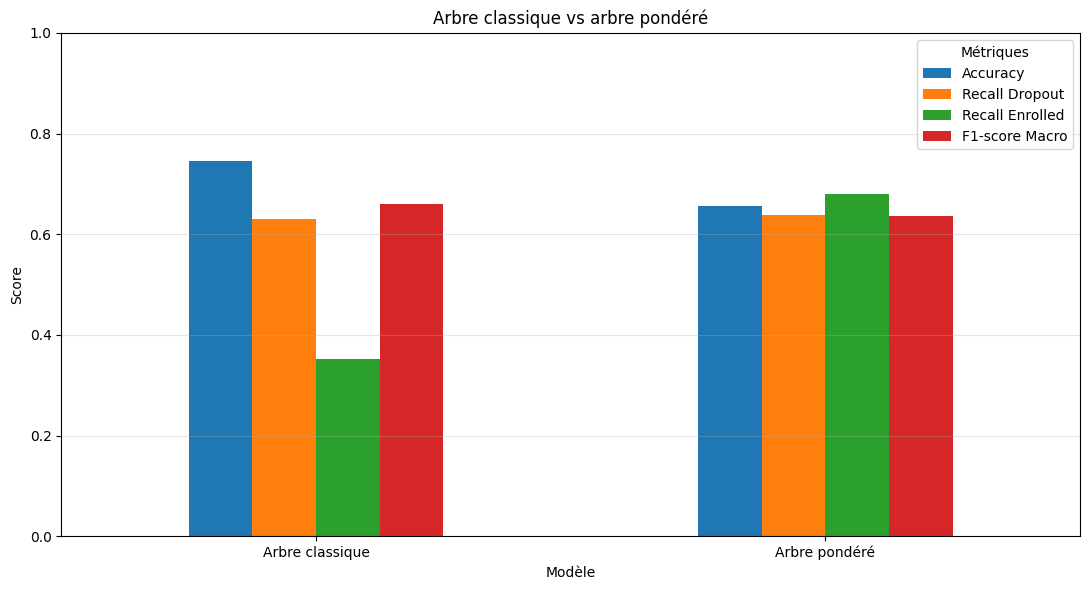

In [51]:
comparaison_arbres = pd.DataFrame({
    "Modèle": ["Arbre classique", "Arbre pondéré"],
    "Accuracy": [accuracy_final, accuracy_weighted],
    "Recall Dropout": [
        metrics_final.loc[metrics_final["Classe"] == "Dropout", "Recall"].iloc[0],
        metrics_weighted.loc[metrics_weighted["Classe"] == "Dropout", "Recall"].iloc[0]
    ],
    "Recall Enrolled": [
        metrics_final.loc[metrics_final["Classe"] == "Enrolled", "Recall"].iloc[0],
        metrics_weighted.loc[metrics_weighted["Classe"] == "Enrolled", "Recall"].iloc[0]
    ],
    "F1-score Macro": [f1_macro_final, f1_macro_weighted]
})

display(comparaison_arbres.round(4))

comparaison_arbres.set_index("Modèle")[
    ["Accuracy", "Recall Dropout", "Recall Enrolled", "F1-score Macro"]
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0)
plt.title("Arbre classique vs arbre pondéré")
plt.xlabel("Modèle")
plt.ylabel("Score")
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Interprétation

| Modèle | Accuracy | Recall Dropout | Recall Enrolled | F1 Macro |
|---|---|---|---|---|
| Arbre classique | 0,7458 | 0,6303 | 0,3522 | 0,6606 |
| Arbre pondéré | 0,6554 | 0,6373 | 0,6792 | 0,6364 |


L'arbre pondéré améliore la détection de la classe `Enrolled`. Son recall passe de **0,3522 à 0,6792**. Il reconnaît donc une plus grande partie des étudiants de cette classe.

Le recall de `Dropout` augmente légèrement, de 0,6303 à 0,6373.

Cependant, cette amélioration a un coût : l'accuracy diminue de **74,58 % à 65,54 %** et le F1-score Macro passe de **0,6606 à 0,6364**.

La reconnaissance de `Graduate` diminue également : son recall passe de 0,9615 à 0,6584.

La pondération permet donc de mieux reconnaître les classes moins représentées, mais elle ne donne pas le meilleur résultat global dans notre expérience.

Le choix dépend de l'objectif : l'arbre classique offre une meilleure performance générale, tandis que l'arbre pondéré détecte davantage d'étudiants `Enrolled`.

## 15. Conclusion

Ce notebook a réalisé l’exploration, la préparation et la modélisation du problème de prédiction du statut académique des étudiants.

### Pipeline retenu

1. Contrôle de la qualité des données.
2. Analyse des variables et des distributions.
3. Séparation stratifiée Train/Test.
4. Nouvelle séparation du Train en sous-entraînement/validation.
5. Construction manuelle d’un arbre avec **Entropie + Gain d’information**.
6. Sélection des variables à partir du sous-entraînement uniquement.
7. Comparaison Top 5 / Top 10 / toutes les variables sur la validation.
8. Optimisation de `max_depth`, `min_samples_split` et `min_gain` sur la validation.
9. Reconstruction du modèle final sur tout le train.
10. Évaluation finale sur le test, utilisé une seule fois.
11. Comparaison avec un arbre pondéré pour mieux traiter le déséquilibre des classes.


### Résultats principaux

- Le dataset contient 4 424 étudiants et 36 variables explicatives.
- La variable la plus importante est `Curricular units 2nd sem (approved)`, qui représente environ **65,4 % de l'importance totale**.
- Le Top 10 a été retenu car il donne des résultats proches de ceux obtenus avec les 36 variables, tout en utilisant moins de variables.
- Les meilleurs hyperparamètres trouvés sont une profondeur de 5, un minimum de 40 observations par séparation et un gain minimum de 0,001.


### Limites du travail

- La classe `Enrolled` reste difficile à reconnaître avec l'arbre classique.
- Les variables du deuxième semestre sont très importantes, mais elles ne sont disponibles qu'en cours d'année. Le modèle est donc moins adapté à une prédiction dès l'inscription.
- Le gain d'information peut favoriser les variables qui possèdent beaucoup de modalités.
- Les résultats pourraient être plus fiables avec une validation croisée stratifiée et d'autres essais de paramètres.




## 16. Exportation des données

Les fichiers exportés correspondent directement au pipeline de l’arbre manuel.

- `train_tree.csv` : ensemble complet d’entraînement, avec `Target`.
- `test_tree.csv` : ensemble de test, avec `Target`, réservé à l’évaluation finale.
- `feature_types.csv` : correspondance entre variables catégorielles et numériques.



In [52]:
import os

# Création du dossier d'export
os.makedirs("../new data", exist_ok=True)

# 1. Sélection des Top 10 features

X_train_top10 = X_train_tree[selected_features].copy()
X_test_top10 = X_test_tree[selected_features].copy()

# Ajouter la variable cible
train_export = X_train_top10.copy()
train_export["Target"] = y_train_tree.values

test_export = X_test_top10.copy()
test_export["Target"] = y_test_tree.values

# 2. Export Train / Test

train_path = "../new data/train_top10.csv"
test_path = "../new data/test_top10.csv"

train_export.to_csv(train_path, index=False)
test_export.to_csv(test_path, index=False)

# 3. Export des types des variables

categorical_top10 = [
    col for col in selected_features
    if col in categorical_cols
]

numerical_top10 = [
    col for col in selected_features
    if col in numerical_cols
]

feature_types_top10 = pd.DataFrame({
    "Feature": categorical_top10 + numerical_top10,
    "Type": (
        ["Categorical"] * len(categorical_top10)
        + ["Numerical"] * len(numerical_top10)
    )
})

feature_types_path = "../new data/feature_types_top10.csv"
feature_types_top10.to_csv(feature_types_path, index=False)


# 4. Vérification
print("Exportation terminée.")
print()
print(f"Train : {train_path}")
print(f"Test  : {test_path}")
print(f"Types : {feature_types_path}")
print()
print(f"Nombre de features exportées : {len(selected_features)}")
print()
print("Top 10 features :")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print()
print("Dimensions :")
print(f"Train : {train_export.shape}")
print(f"Test  : {test_export.shape}")

Exportation terminée.

Train : ../new data/train_top10.csv
Test  : ../new data/test_top10.csv
Types : ../new data/feature_types_top10.csv

Nombre de features exportées : 10

Top 10 features :
1. Curricular units 2nd sem (approved)
2. Tuition fees up to date
3. Course
4. Curricular units 1st sem (evaluations)
5. Curricular units 1st sem (approved)
6. Curricular units 2nd sem (enrolled)
7. Previous qualification (grade)
8. Admission grade
9. Curricular units 2nd sem (credited)
10. Curricular units 2nd sem (grade)

Dimensions :
Train : (3539, 11)
Test  : (885, 11)
